# Practice 3 — Hugging Face
Hai bài: suy luận bằng mô hình có sẵn và fine-tune DistilBERT trên IMDb. Chọn kernel `.venv` Python 3.11 trước khi chạy.

In [4]:
from pathlib import Path
import sys, subprocess
assert Path("exercise1_sentiment.py").exists(), "Hãy mở notebook từ thư mục project."
print(sys.executable)

c:\Program Files\Python314\python.exe


## Exercise 1
Tải tokenizer và mô hình SST-2, chuyển câu thành token/ID, dự đoán nhãn. Dùng câu tiếng Anh.

In [5]:
from exercise1_sentiment import run
results = run(["I really enjoyed this movie!", "The movie was boring and disappointing."])

[
  {
    "text": "I really enjoyed this movie!",
    "tokens": [
      "i",
      "really",
      "enjoyed",
      "this",
      "movie",
      "!"
    ],
    "input_ids": [
      101,
      1045,
      2428,
      5632,
      2023,
      3185,
      999,
      102
    ],
    "label": "POSITIVE",
    "score": 0.9998719692230225
  },
  {
    "text": "The movie was boring and disappointing.",
    "tokens": [
      "the",
      "movie",
      "was",
      "boring",
      "and",
      "disappointing",
      "."
    ],
    "input_ids": [
      101,
      1996,
      3185,
      2001,
      11771,
      1998,
      15640,
      1012,
      102
    ],
    "label": "NEGATIVE",
    "score": 0.9997933506965637
  }
]


## Exercise 2
Script tải IMDb, tách train/validation, tokenize, khởi tạo mô hình và Trainer. Chạy thử 64 mẫu trước; sau đó đổi thành 2000/500/500 và 2 epoch. Test không dùng chọn checkpoint.

In [6]:
subprocess.run([sys.executable, "exercise2_finetune.py", "--train-size", "64", "--val-size", "32", "--test-size", "32", "--epochs", "1"], check=True)

CompletedProcess(args=['c:\\Program Files\\Python314\\python.exe', 'exercise2_finetune.py', '--train-size', '64', '--val-size', '32', '--test-size', '32', '--epochs', '1'], returncode=0)

## Đánh giá
Đọc chỉ số thực tế và biểu đồ. Kết quả ít dữ liệu chỉ chứng minh luồng chạy.

{'test_loss': 0.6923782229423523, 'test_accuracy': 0.5625, 'test_precision': 0.5555555555555556, 'test_recall': 0.625, 'test_f1': 0.5882352941176471, 'test_runtime': 2.9488, 'test_samples_per_second': 10.852, 'test_steps_per_second': 1.356}
              precision    recall  f1-score   support

    NEGATIVE       0.57      0.50      0.53        16
    POSITIVE       0.56      0.62      0.59        16

    accuracy                           0.56        32
   macro avg       0.56      0.56      0.56        32
weighted avg       0.56      0.56      0.56        32



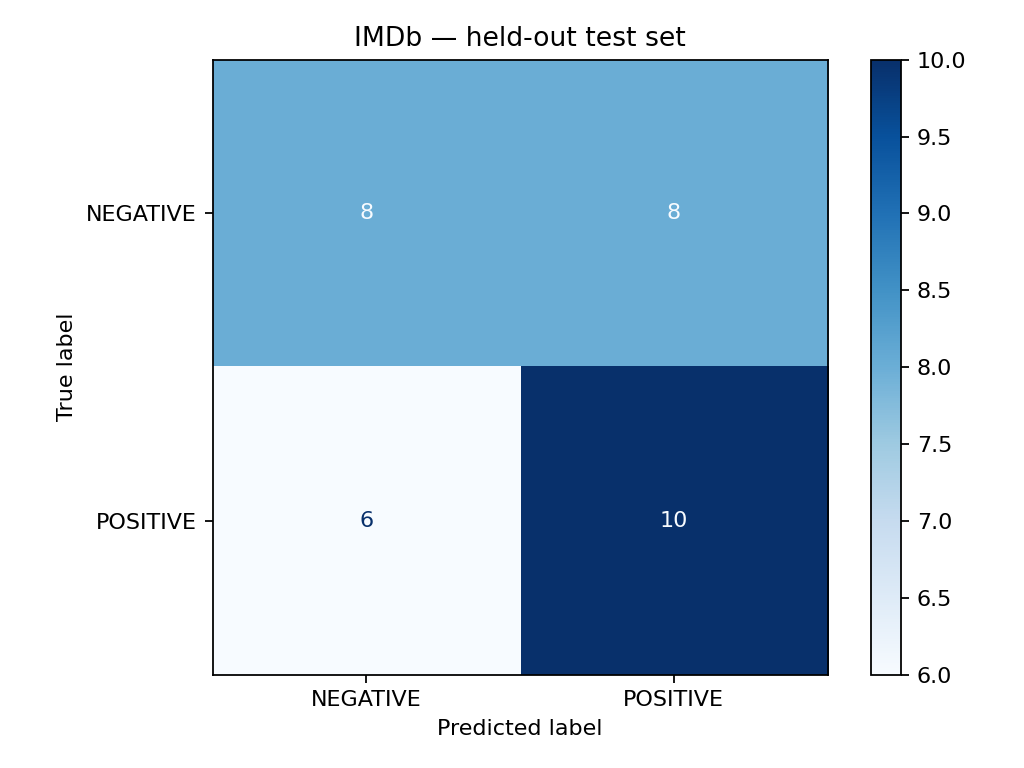

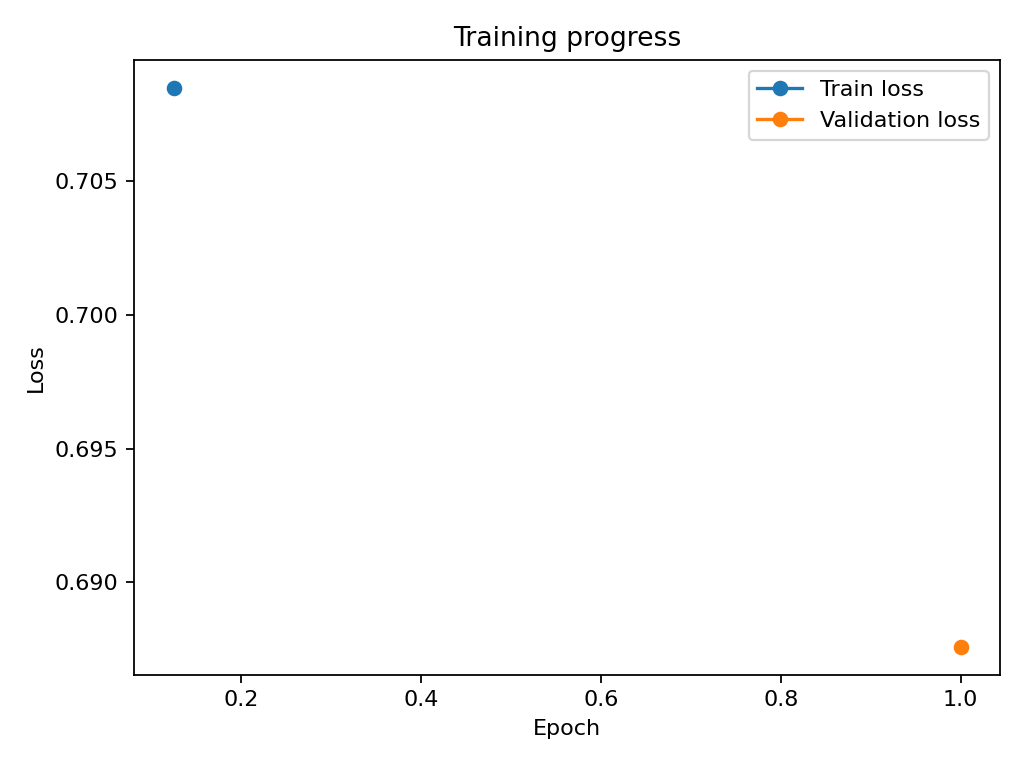

In [7]:
import json
from IPython.display import display, Image
out = Path("outputs/finetune")
print(json.loads((out / "metrics.json").read_text()))
print((out / "classification_report.txt").read_text())
display(Image(filename=str(out / "confusion_matrix.png")))
display(Image(filename=str(out / "loss_curve.png")))

## Dự đoán bằng mô hình đã huấn luyện

In [8]:
subprocess.run([sys.executable, "predict.py", "--text", "The acting was excellent!", "This film was terrible."], check=True)

CompletedProcess(args=['c:\\Program Files\\Python314\\python.exe', 'predict.py', '--text', 'The acting was excellent!', 'This film was terrible.'], returncode=0)

## Nhận xét
Sau khi chạy: ghi accuracy/F1, lớp dễ nhầm, diễn biến loss, ảnh hưởng số mẫu và epoch. Không điền số liệu chưa chạy thực tế.